# Robustez e cenários operacionais: o que acontece quando o plano encontra a realidade?

**Quão frágeis são planos otimizados quando a execução atrasa e o plano não é refeito? E o que muda, no solver, com capacidade menor, frota limitada (com clientes prioritários) e janelas flexíveis, e quão estável é a reotimização quando alguns clientes entram ou saem?** Este notebook lê resultados já produzidos e congelados (`outputs/frozen/phase_c/`); nenhum solver é executado aqui.

**Protocolo pré-registrado (Nosek et al., 2018)** (`reports/protocolo-fase-c.md`, registrado e esclarecido antes da execução; resultados em `reports/fase-c-robustez.md`). A fase responde aos achados 1 e 2 da auditoria externa (`reports/plano-sanidade-auditoria.md`): a camada B ainda não tinha descarte de clientes, prioridade, limite de frota ou atrasos, e a fragilidade dos planos não havia sido medida. Há quatro blocos:

- **C1, robustez do plano fixo (sem solver; Gendreau et al., 1996):** os planos congelados da avaliação (OR-Tools [Perron & Furnon, 2026] na réplica mediana e as duas baselines, 42 instâncias) são executados sem replanejar sob choques de tempo de viagem (× (1 + ε), ε ~ U(0, a), com a = 5%, 10% e 20%), de tempo de serviço (até +20%) e da combinação (viagem até +10% e serviço até +20%), com 1 000 sorteios de Monte Carlo (Metropolis & Ulam, 1949) por plano e cenário e semente fixa; uma chegada depois do fim da janela é registrada como **atraso**, e o serviço acontece mesmo assim. Aqui as instâncias de avaliação são usadas **só de forma descritiva** (nada é ajustado).
- **C2, cenários com o solver (só as 14 instâncias de desenvolvimento):** C2.1 capacidade reduzida (100%, 90% e 80% de Q); C2.2 frota limitada com descarte penalizado (Archetti et al., 2014) e **prioridade** (K igual à frota de referência menos 1 e menos 2; 20% dos clientes prioritários, com penalidade 10 vezes maior); C2.3 janelas flexíveis, com atraso penalizado (Taillard et al., 1997).
- **C3, estabilidade da reotimização (só desenvolvimento; Pillac et al., 2013):** remover ou inserir 10% dos clientes e reotimizar, com partida a quente (do plano anterior) ou a frio, contra um patamar de ruído.

**Camada B: nenhuma comparação com o SINTEF em nenhum ponto.** Cada cenário é comparado com o **plano de referência da mesma instância** (o solver v2, escala 10 000, em 30 s e 3 réplicas, na instância sem alteração; réplica representativa lexicográfica, definida neste projeto, a 2ª de 3). Em C2.2 e C2.3, a réplica representativa é escolhida por critérios próprios (menos prioritários e clientes descartados em C2.2; menos clientes atrasados e menor atraso total em C2.3), fixados antes da execução porque a regra geral (veículos, distância) favoreceria um plano que descarta ou atrasa mais. Todos os resultados são descritivos; o objetivo do solver continua sendo frota e depois distância, e robustez e tempo não são otimizados.

## 1. Preparação do ambiente

Nesta seção são carregados a divisão das instâncias, a configuração efetiva (`config/experiment.toml`) e os resultados congelados de cada bloco; os carregadores recusam instâncias do conjunto errado (C1 só aceita instâncias de avaliação; C2 e C3, só de desenvolvimento). A primeira tabela mostra a configuração efetiva da fase; a segunda audita o C1 (planos testados, cenários e sorteios por método); a terceira audita os blocos com solver (células, instâncias, factibilidade segundo o verificador em precisão dupla e tempo médio).

In [1]:
LANG = "pt"  # "pt" or "en"

import matplotlib.pyplot as plt
from IPython.display import display

from delivery_routing_vrptw import (
    benchmark,
    config,
    eda,
    paths,
    phase_c_view,
    results,
    viz_robustness,
)
from delivery_routing_vrptw.viz import setup_notebook_figures

setup_notebook_figures()

P = paths.data_paths()
R = paths.result_paths()
split = benchmark.read_split(P["split"])
cfg = config.load_config()
robustness = results.load_robustness(R["phase_c_C1"], split)
capacity = results.load_phase_c_cells(R["phase_c_capacity"], split)
fleet = results.load_phase_c_cells(R["phase_c_fleet_priority"], split)
soft = results.load_phase_c_cells(R["phase_c_soft_windows"], split)
removal = results.load_phase_c_cells(R["phase_c_removal"], split)
insertion = results.load_phase_c_cells(R["phase_c_insertion"], split)
reference = phase_c_view.reference_plans(capacity)
blocks = {
    "capacity": capacity,
    "fleet_priority": fleet,
    "soft_windows": soft,
    "removal": removal,
    "insertion": insertion,
}

display(eda.localize_columns(phase_c_view.config_table(cfg, LANG), LANG))
display(eda.localize_columns(phase_c_view.robustness_integrity(robustness["cells"], LANG), LANG))
display(eda.localize_columns(phase_c_view.block_overview(blocks, LANG), LANG))

,Indicador,Valor
0,Solver (estratégia de frota + solução inicial ...,fixed_cost + SAVINGS + GUIDED_LOCAL_SEARCH
1,Escala inteira e custo fixo relativo,"10000, k = 10"
2,Orçamento por execução (s) · réplicas · processos,30 · 3 · 8
3,Semente dos sorteios,20261118
4,C1: sorteios · choque de viagem · choque de se...,"1000 · 5%, 10%, 20% · 20% · 10%"
5,C2.1: capacidade (fração de Q),"100%, 90%, 80%"
6,C2.2: frota limitada · prioritários · penalida...,"K − 1, K − 2 · 20% · 10×"
7,C2.3: frota limitada · custo do atraso (× cust...,"K − 1 · 1×, 10×"
8,C3: parcela de clientes removida ou inserida,10%


,Método,Nº de instâncias,Planos testados,Cenários de choque,Sorteios por plano e cenário
0,OR-Tools,42,42,5,1000
1,Vizinho mais próximo com janelas,42,42,5,1000
2,Gulosa por prazo,42,42,5,1000


,Bloco,Células,Nº de instâncias,Factíveis,Tempo médio (s)
0,C2.1 · capacidade reduzida,126,14,126,30.0
1,C2.2 · frota limitada com prioridade,168,14,168,30.0
2,C2.3 · janelas flexíveis,84,14,18,7.0
3,C3 · remoção de 10%,84,14,84,30.0
4,C3 · inserção de 10%,98,14,98,30.0


**Insight.** A configuração efetiva confere com o protocolo: solver `fixed_cost` + `SAVINGS` + `GUIDED_LOCAL_SEARCH` com escala 10 000 e custo fixo relativo k = 10, 30 s por execução, 3 réplicas e 8 processos, semente 20261118; C1 com 1 000 sorteios, choques de viagem de 5%, 10% e 20%, de serviço de 20% e combinado de 10% e 20%; C2.1 com 100%, 90% e 80% da capacidade; C2.2 com K − 1 e K − 2, 20% de prioritários e penalidade 10×; C2.3 com K − 1 e atraso a 1× e 10× o custo da distância; C3 com 10% dos clientes. No C1, os três métodos têm 42 planos testados (42 instâncias de avaliação), 5 cenários de choque e 1 000 sorteios por plano e cenário. Os blocos com solver têm 126 células (C2.1: 14 instâncias × 3 capacidades × 3 réplicas), 168 (C2.2: 14 × 2 frotas × 2 variantes × 3), 84 (C2.3: 14 × 2 custos × 3), 84 (remoção) e 98 (inserção: 84 reotimizações mais 14 planos-base com 90% dos clientes), todas de 14 instâncias de desenvolvimento. Todas as células são factíveis, **exceto** as do C2.3: só 18 das 84 são factíveis (isto é a causa de a seção 5 ser pouco informativa). O tempo médio é 30,0 s nos blocos que usam o orçamento inteiro e 7,0 s no C2.3, porque muitas execuções falham quase de imediato. **Limitações:** a factibilidade aqui é contra a instância transformada de cada cenário (capacidade reduzida, clientes retirados), não contra a instância original; as réplicas representativas de C2.2 e C2.3 seguem critérios próprios, e não a regra geral. **Próxima decisão:** ler primeiro a robustez dos planos fixos (C1).

## 2. C1 — Robustez do plano fixo sob atrasos

**Pergunta:** quando as viagens ou os serviços demoram mais do que o planejado (Gendreau et al., 1996) e o plano não é refeito, que parcela dos clientes é atendida depois do fim da janela, e o plano do OR-Tools é mais frágil que o das baselines? **O que se mostra:** por cenário de choque e método, médias sobre os 42 planos de: clientes atendidos com atraso (%), retornos ao depósito depois do horizonte (%), rotas com pelo menos um cliente atrasado (%), e o atraso médio e o P95 entre os clientes atrasados (em unidades de tempo da instância); e um gráfico com os clientes atrasados por cenário (a) e a taxa de atraso por faixa de folga nominal no cenário de viagem +0–10% (b). Os choques são independentes por trecho e por cliente, com os mesmos números aleatórios entre cenários para cada instância e método.

,Cenário,Método,Planos,Clientes atrasados (%),Retorno tardio ao depósito (%),Rotas com ≥ 1 atraso (%),Atraso médio entre atrasados,Atraso P95 entre atrasados
0,Viagem +0–5%,OR-Tools,42,4.6,9.6,55.6,1.7,3.0
1,Viagem +0–5%,Vizinho mais próximo com janelas,42,5.6,19.5,44.2,2.9,6.0
2,Viagem +0–5%,Gulosa por prazo,42,13.4,32.2,56.6,3.5,7.6
3,Viagem +0–10%,OR-Tools,42,6.3,13.4,63.8,3.9,6.9
4,Viagem +0–10%,Vizinho mais próximo com janelas,42,9.3,32.9,53.5,5.5,12.0
5,Viagem +0–10%,Gulosa por prazo,42,21.1,43.3,66.9,7.4,15.9
6,Viagem +0–20%,OR-Tools,42,9.3,18.4,70.2,8.1,14.9
7,Viagem +0–20%,Vizinho mais próximo com janelas,42,16.0,45.7,63.8,11.8,25.3
8,Viagem +0–20%,Gulosa por prazo,42,31.7,55.7,77.3,16.0,34.6
9,Serviço +0–20%,OR-Tools,42,16.6,22.9,84.2,23.9,56.3


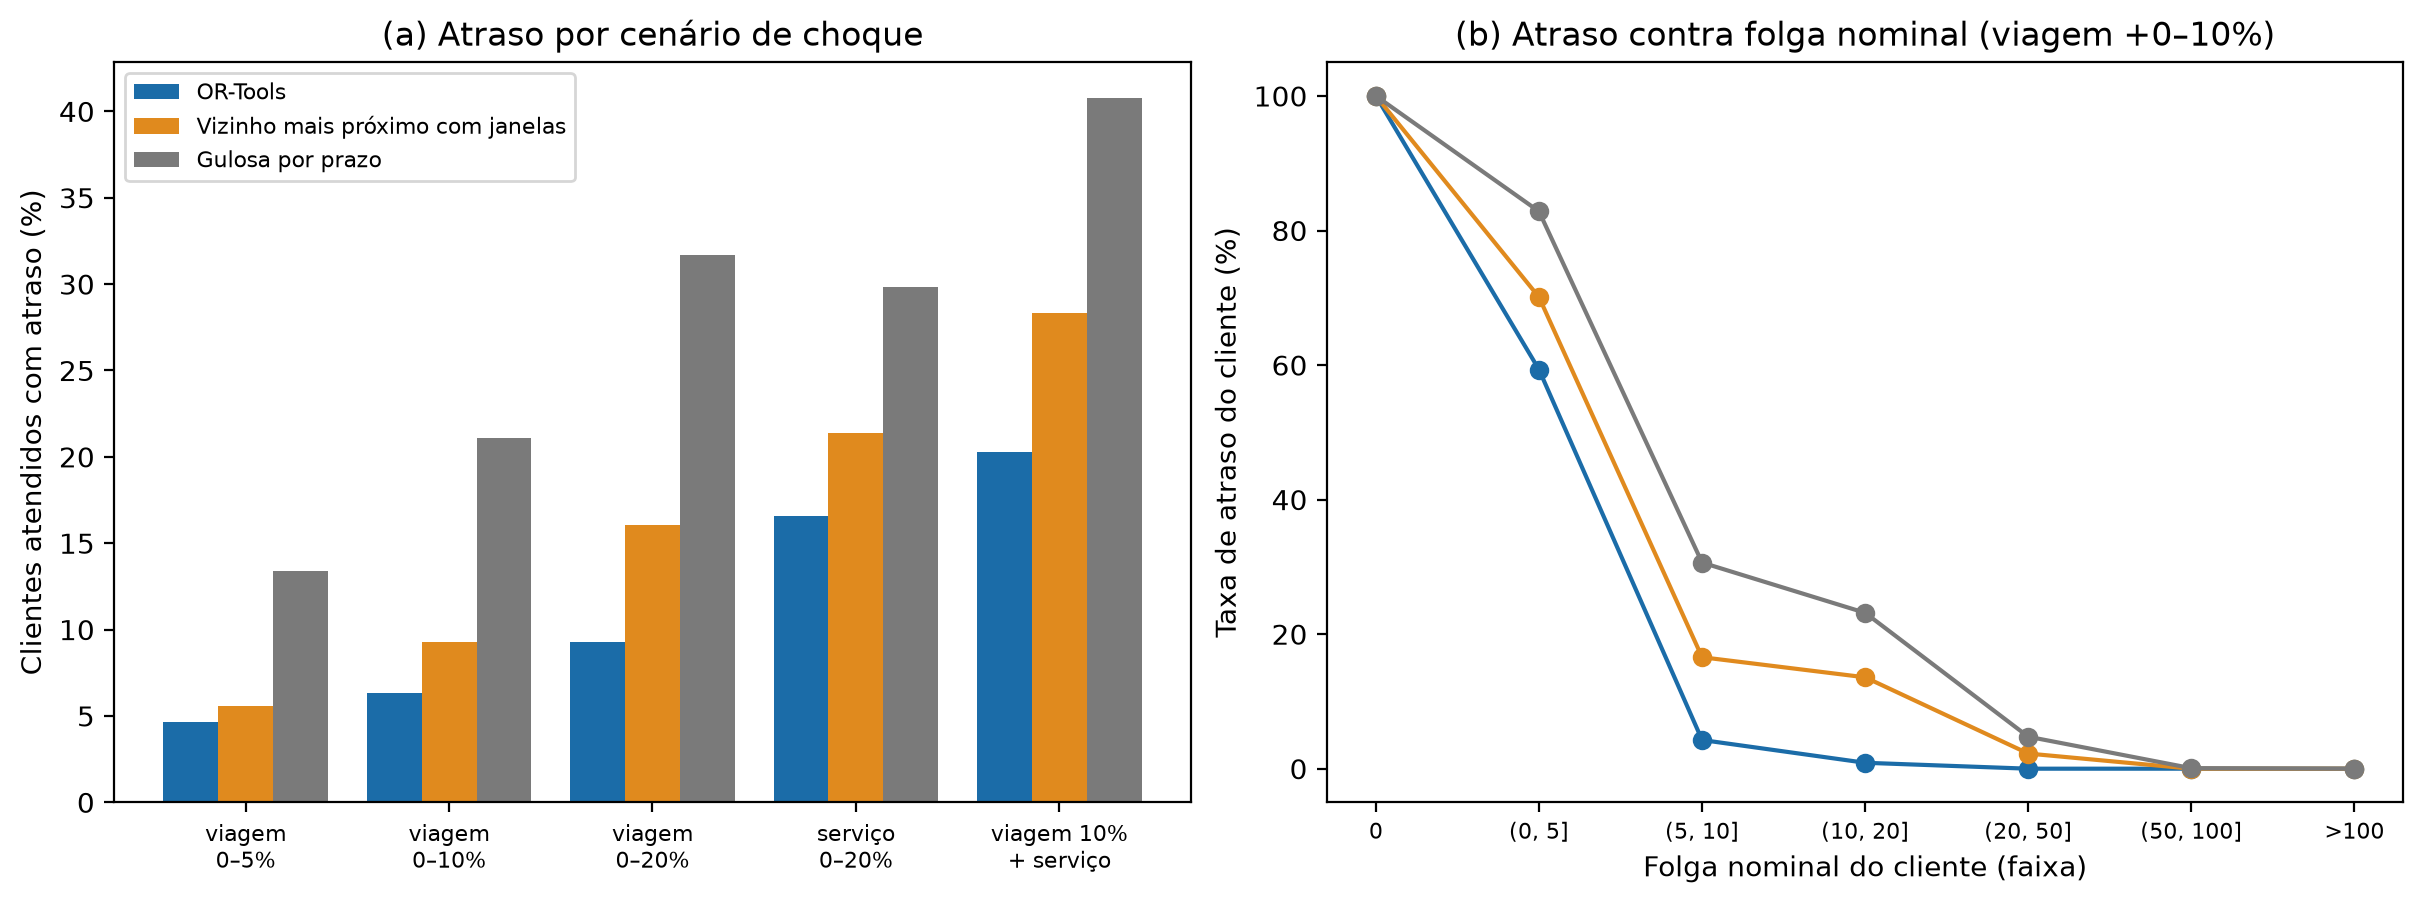

In [2]:
display(eda.localize_columns(phase_c_view.robustness_table(robustness["summary"], "overall", LANG), LANG))

viz_robustness.plot_robustness(robustness["summary"], robustness["slack_lateness"], LANG)
plt.show()

**Insight.** O plano otimizado **não é mais frágil que as baselines por cliente**: com viagem +0–10%, 6,3% dos clientes do OR-Tools são atendidos com atraso, contra 9,3% (vizinho mais próximo) e 21,1% (gulosa); em todos os cinco cenários o OR-Tools tem a menor parcela (de 4,6% com viagem +0–5% a 20,3% com viagem e serviço, contra 5,6% a 28,3% e 13,4% a 40,8%). O retorno tardio ao depósito é cerca de 2 a 3 vezes menor no OR-Tools nos cenários de viagem (por exemplo, 13,4% contra 32,9% e 43,3% com +0–10%) e de 22,9% contra 51,3% e 53,3% com serviço +0–20%. Por **rota**, porém, o quadro é outro: o OR-Tools tem mais rotas com algum atraso que o vizinho mais próximo em todos os cenários (55,6% contra 44,2% com viagem +0–5%; 84,2% contra 71,1% com serviço) e mais que a gulosa sob choque de serviço (84,2% contra 72,5%; 89,9% contra 84,3% no combinado), embora menos que a gulosa nos cenários de viagem (63,8% contra 66,9% com +0–10%). Isso é compatível com o OR-Tools usar menos veículos, com rotas mais longas e mais clientes, de modo que um único atraso acumulado basta para marcar a rota, mas essa explicação não foi testada. O atraso nunca é desprezível: mesmo com viagem +0–5%, mais da metade das rotas do OR-Tools (55,6%) e da gulosa (56,6%) tem algum cliente atrasado. Entre os clientes atrasados, o atraso médio do OR-Tools cresce de 1,7 (viagem +0–5%) para 23,9 (serviço +0–20%) e 26,7 (combinado). **Limitações:** são 42 instâncias de avaliação usadas de forma descritiva, com um plano por instância e método; os choques são independentes entre trechos, sem a correlação espacial e temporal do trânsito real; os valores são médias sobre planos de instâncias de escalas muito diferentes; o solver não otimiza robustez. **Próxima decisão:** ver o que explica a fragilidade, a folga nominal.

**Pergunta:** a fragilidade de um cliente é explicada pela folga que o plano nominal lhe dá (a diferença entre o fim da janela e o início do serviço)? **O que se mostra:** a correlação de postos de Spearman (Spearman, 1904), por cenário e método, entre a folga nominal de cada cliente e a sua taxa de atraso nos sorteios (esperada: negativa), e a taxa de atraso (em %) por faixa de folga nominal no cenário de viagem +0–10%, com o número de clientes de cada faixa nos planos do OR-Tools. Folga 0 significa que o serviço nominal já começa no fim da janela.

In [3]:
display(eda.localize_columns(phase_c_view.slack_correlation_table(robustness["slack_correlation"], LANG), LANG))
display(eda.localize_columns(phase_c_view.slack_bins_table(robustness["slack_lateness"], "travel_0.10", LANG), LANG))

,Cenário,OR-Tools,Vizinho mais próximo com janelas,Gulosa por prazo
0,Viagem +0–5%,-0.41,-0.45,-0.63
1,Viagem +0–10%,-0.48,-0.54,-0.71
2,Viagem +0–20%,-0.57,-0.63,-0.78
3,Serviço +0–20%,-0.37,-0.42,-0.54
4,Viagem +0–10% e serviço +0–20%,-0.47,-0.54,-0.67


,Folga nominal (faixa),Nº de clientes,OR-Tools,Vizinho mais próximo com janelas,Gulosa por prazo
0,0,114,100.0,100.0,100.0
1,"(0, 5]",231,59.3,70.1,82.8
2,"(5, 10]",305,4.3,16.6,30.6
3,"(10, 20]",245,0.9,13.6,23.2
4,"(20, 50]",716,0.0,2.3,4.8
5,"(50, 100]",878,0.0,0.0,0.1
6,>100,1711,0.0,0.0,0.0


**Insight.** A correlação entre folga e taxa de atraso é **negativa em todos os 15 casos** (5 cenários × 3 métodos): de −0,37 (OR-Tools, serviço +0–20%) a −0,78 (gulosa, viagem +0–20%); no OR-Tools vai de −0,37 a −0,57, no vizinho mais próximo de −0,42 a −0,63 e na gulosa de −0,54 a −0,78. Quanto mais folga, menos atraso, e o efeito é forte nas faixas baixas: com viagem +0–10%, os 114 clientes do OR-Tools sem folga atrasam em 100% dos sorteios, os 231 com folga de até 5 em 59,3%, os 305 entre 5 e 10 em 4,3% e os 245 entre 10 e 20 em 0,9%; acima de 20 de folga o OR-Tools não atrasa (716, 878 e 1 711 clientes nas três últimas faixas). Nas mesmas faixas, as baselines atrasam mais: de até 5 de folga, 70,1% (vizinho mais próximo) e 82,8% (gulosa); entre 5 e 10, 16,6% e 30,6%; entre 10 e 20, 13,6% e 23,2%. Ou seja, a menor fragilidade por cliente do OR-Tools da seção anterior não vem só de ter mais folga: dentro da mesma faixa de folga nominal ele também atrasa menos, mas a causa disso (por exemplo, a posição do cliente na rota) não foi investigada. **Limitações:** a correlação é entre postos e não indica causalidade; as faixas de folga misturam clientes de instâncias de escalas muito diferentes (folgas em unidades de tempo da instância); a faixa de folga 0 reúne clientes cujo serviço nominal já começa no fim da janela, de modo que qualquer atraso positivo os atrasa. **Próxima decisão:** ver como a fragilidade varia por família.

**Pergunta:** a fragilidade depende do tipo de instância? **O que a tabela mostra:** por família e no cenário de viagem +0–10%, o número de planos, a folga nominal média dos planos do OR-Tools e o percentual de clientes atendidos com atraso em cada método.

In [4]:
display(eda.localize_columns(phase_c_view.robustness_by_family(robustness["summary"], "travel_0.10", LANG), LANG))

,Família,Planos,Folga nominal média (OR-Tools),OR-Tools,Vizinho mais próximo com janelas,Gulosa por prazo
0,C1,7,168.1,1.0,2.5,10.8
1,C2,6,438.7,1.2,2.0,9.5
2,R1,9,37.6,13.1,14.4,24.2
3,R2,8,237.9,4.9,11.7,26.1
4,RC1,6,41.1,11.1,8.7,21.7
5,RC2,6,193.0,4.7,14.1,32.9


**Insight.** No OR-Tools, com viagem +0–10%, a parcela de clientes atrasados é de 13,1% em R1 e 11,1% em RC1 (folga nominal média de 37,6 e 41,1), contra 1,0% em C1 e 1,2% em C2 (folga de 168,1 e 438,7), 4,9% em R2 (237,9) e 4,7% em RC2 (193,0). A fragilidade acompanha a folga: as famílias de janelas estreitas e horizonte curto (R1 e RC1) concentram o atraso, e as de janelas largas ou clientes agrupados (C1, C2, R2, RC2) quase não atrasam. A ordem entre os métodos se mantém na maioria das famílias (OR-Tools 1,0%, vizinho mais próximo 2,5% e gulosa 10,8% em C1; 4,9%, 11,7% e 26,1% em R2), com uma exceção: em RC1, o vizinho mais próximo (8,7%) atrasa menos clientes que o OR-Tools (11,1%). **Limitações:** são de 6 a 9 planos por família; a folga média mistura escalas diferentes de instância; a exceção de RC1 não foi investigada. **Próxima decisão:** passar aos cenários com o solver, começando pela capacidade reduzida.

## 3. C2.1 — Capacidade reduzida

**Pergunta:** se a capacidade dos veículos cai para 90% e 80% de Q (por exemplo, veículos parcialmente ocupados ou menores), quantos veículos a mais são necessários e a que custo de distância? **O que se mostra:** por fator de capacidade e **classe de frota** contra o plano de referência da mesma instância (frota igual ou maior), o número de instâncias, os veículos adicionais (média) e a variação da distância (média e mediana, em %) **só dentro da classe**, porque a distância de planos com frotas diferentes não é comparável; a linha "todas" traz os veículos adicionais em média sobre as 14 instâncias e as células infactíveis; e a lista das instâncias cuja frota cresce. Modelo rígido, resolvido de novo em cada capacidade (3 réplicas, 30 s).

In [5]:
display(eda.localize_columns(phase_c_view.capacity_by_level(capacity, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.capacity_instances(capacity, reference, LANG), LANG))

,Nível,Frota contra o plano-base,Nº de instâncias,Células infactíveis,Veículos adicionais (média),"Variação da distância, média (%)","Variação da distância, mediana (%)"
0,80%,todas,14,0,0.57,NaN,NaN
1,80%,frota igual,8,0,0.00,0.24,0.00
2,80%,frota maior,6,0,1.33,13.56,10.72
3,90%,todas,14,0,0.21,NaN,NaN
4,90%,frota igual,11,0,0.00,-0.52,0.00
5,90%,frota maior,3,0,1.00,13.86,14.73


,Instância,Nível,Veículos (plano de referência),Veículos (cenário),Veículos adicionais,Variação da distância (%)
0,C103,90%,10,11,1,14.7
1,C106,90%,10,11,1,21.1
2,RC108,90%,11,12,1,5.8
3,C103,80%,10,12,2,20.4
4,C106,80%,10,12,2,33.6
5,C203,80%,3,4,1,12.3
6,C206,80%,3,4,1,9.1
7,R111,80%,11,12,1,-1.3
8,RC108,80%,11,12,1,7.2


**Insight.** Com 90% da capacidade, são necessários em média 0,21 veículo a mais por instância: 3 das 14 instâncias (C103, C106 e RC108) usam 1 veículo a mais e 11 mantêm a frota; com 80%, a média é 0,57 e 6 instâncias têm frota maior (1,33 veículo a mais em média: C103 e C106 com +2; C203, C206, R111 e RC108 com +1), enquanto 8 mantêm a frota. Nenhuma célula é infactível. Dentro da classe de frota maior, a distância aumenta em média 13,9% (mediana 14,7%) com 90% e 13,6% (mediana 10,7%) com 80%; com frota igual, a distância praticamente não muda (−0,52% em média com 90%, +0,24% com 80%, mediana 0,0% nos dois). Quatro das seis instâncias que crescem com 80% são das famílias C, em que a capacidade já determinava a frota de referência (razão 1,000 no notebook 02): onde a capacidade é o fator limitante, qualquer redução se traduz em veículos; nas demais, a folga de capacidade absorve a redução. R111 mostra distância menor (−1,3%) com um veículo a mais, valor que não é comparável com o do plano de referência por a frota ser diferente. **Limitações:** só 14 instâncias de desenvolvimento, com 3 a 8 por classe de frota; uma redução uniforme de capacidade é um cenário estilizado; a distância dentro da classe de frota maior mistura instâncias de escalas diferentes. **Próxima decisão:** limitar a frota, o que obriga a deixar clientes sem atendimento.

## 4. C2.2 — Frota limitada com descarte penalizado e prioridade

**Pergunta:** se a frota é menor que a necessária, quantos clientes deixam de ser atendidos, e uma penalidade maior para clientes prioritários os protege? **O que se mostra:** com K igual à frota do plano de referência menos 1 e menos 2, todo cliente pode ser descartado mediante penalidade (Archetti et al., 2014), calibrada para que o solver só descarte quando a frota o impede; 20% dos clientes são prioritários (sorteio por instância, semente fixa), com penalidade 10 vezes maior, e a variante com prioridade é comparada com o **mesmo K com penalidade uniforme**. A primeira tabela agrega as 14 instâncias (clientes e prioritários não atendidos, em total e em %, demanda não atendida média e a variação da distância, que cobre menos clientes e **não é comparável um a um**), com a diferença pareada por instância (prioridade menos uniforme); a segunda lista, por instância, os clientes e os prioritários não atendidos nas duas variantes; o gráfico resume os dois efeitos.

,Nível,Variante,Nº de instâncias,Clientes não atendidos,Prioritários não atendidos,Prioritários não atendidos (%),Comuns não atendidos (%),Demanda não atendida (média),"Variação da distância, média (%)"
0,K − 1,Com prioridade (10×),14,122.0,0.0,0.0,10.9,162.1,-0.4
1,K − 1,Penalidade uniforme,14,111.0,23.0,8.2,7.9,150.6,0.6
2,K − 2,Com prioridade (10×),14,363.0,3.0,1.1,32.1,454.3,-14.0
3,K − 2,Penalidade uniforme,14,344.0,69.0,24.6,24.6,437.7,-20.7
4,K − 1,Diferença (prioridade − uniforme),14,0.8,-1.6,NaN,NaN,11.4,NaN
5,K − 2,Diferença (prioridade − uniforme),14,1.4,-4.7,NaN,NaN,16.6,NaN


,Instância,Nível,Limite de frota K,Clientes prioritários,Não atendidos (uniforme),Não atendidos (com prioridade),Prioritários não atendidos (uniforme),Prioritários não atendidos (com prioridade)
0,C103,K − 1,9,20,1,1,0,0
1,C103,K − 2,8,20,10,9,2,0
2,C106,K − 1,9,20,7,8,3,0
3,C106,K − 2,8,20,15,17,5,0
4,C203,K − 1,2,20,31,32,4,0
5,C203,K − 2,1,20,66,68,12,1
6,C206,K − 1,2,20,31,32,8,0
7,C206,K − 2,1,20,66,69,13,0
8,R108,K − 1,9,20,3,3,0,0
9,R108,K − 2,8,20,10,9,1,0


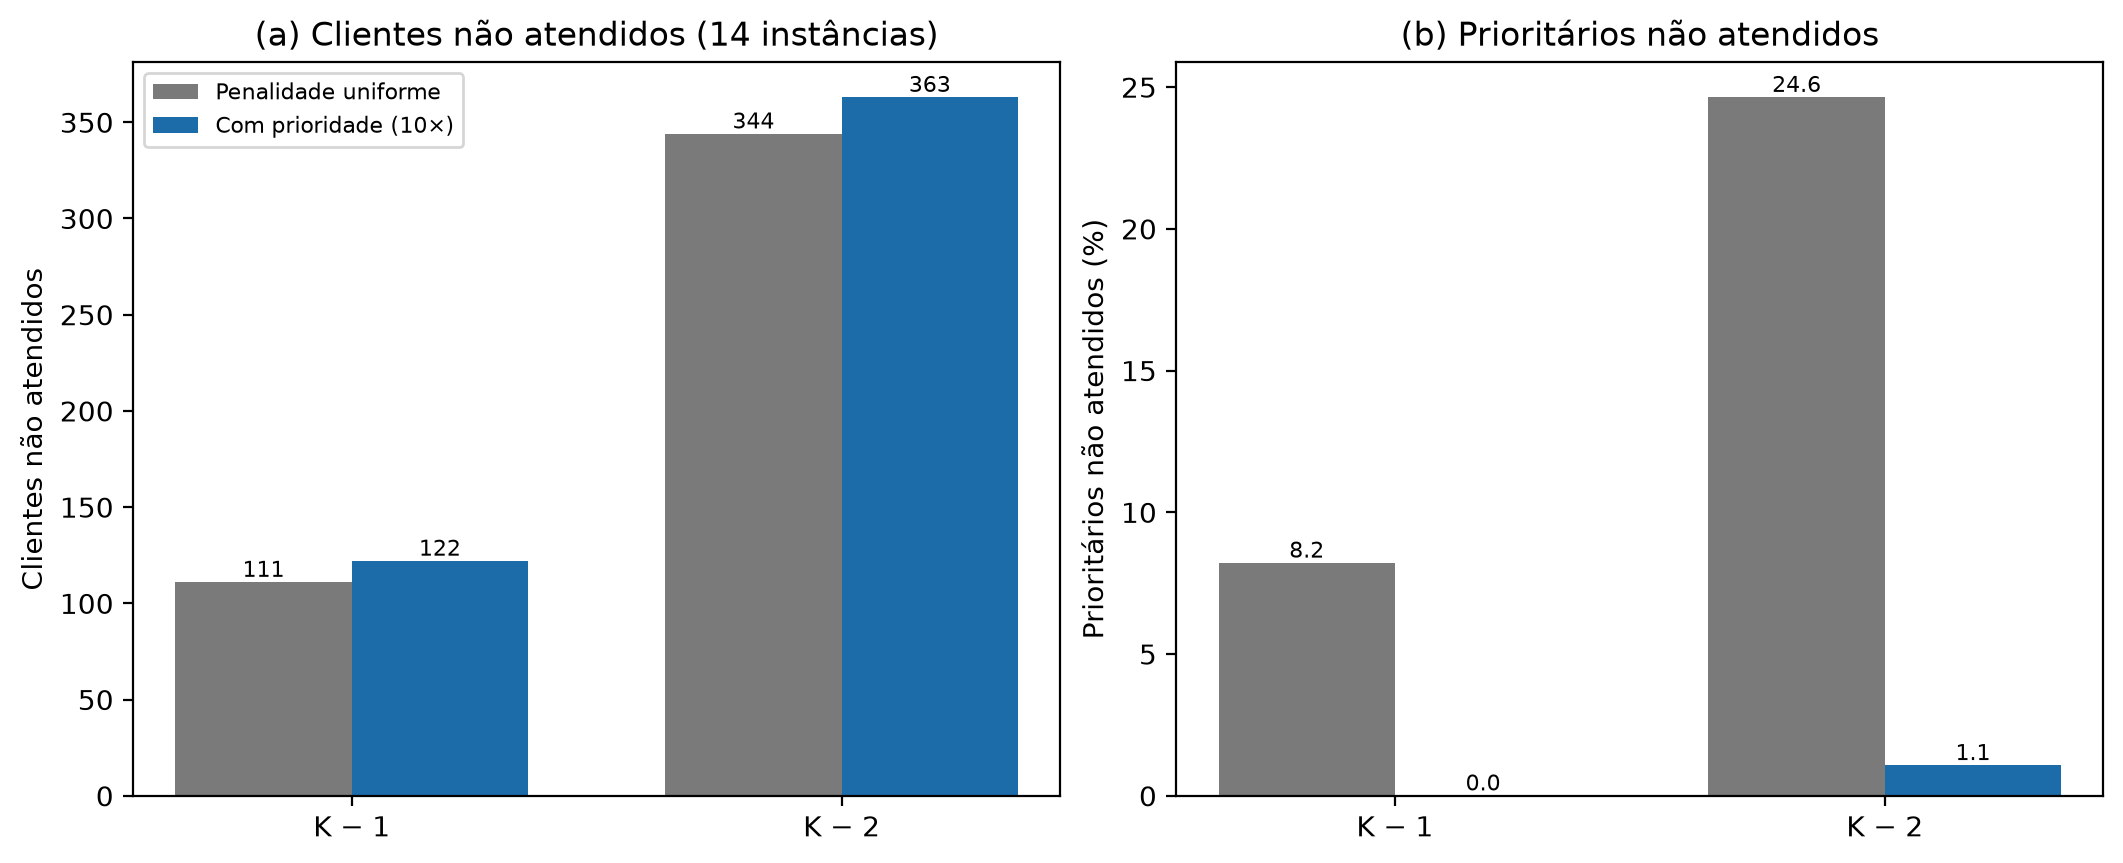

In [6]:
display(eda.localize_columns(phase_c_view.fleet_priority_by_level(fleet, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.fleet_priority_instances(fleet, reference, LANG), LANG))

viz_robustness.plot_fleet_priority(fleet, reference, LANG)
plt.show()

**Insight.** Com um veículo a menos (K − 1), a penalidade uniforme deixa 111 clientes sem atendimento nas 14 instâncias (cerca de 8 por instância, 7,9% dos clientes comuns), dos quais 23 prioritários (8,2% dos prioritários); com a prioridade, são 122 clientes não atendidos e **0 prioritários**. Com dois veículos a menos (K − 2), são 344 clientes (cerca de 25 por instância), 69 prioritários (24,6%), contra 363 clientes e **3 prioritários** (1,1%) com prioridade. A prioridade protege, portanto, quase todos os prioritários (de 23 para 0 e de 69 para 3), ao custo de descartar um pouco mais de clientes comuns: +0,8 e +1,4 cliente por instância, a parcela de comuns não atendidos passa de 7,9% para 10,9% (K − 1) e de 24,6% para 32,1% (K − 2), e a demanda não atendida média sobe 11,4 e 16,6 unidades. Os 3 prioritários que ainda ficam sem atendimento com K − 2 estão em instâncias com K = 1 (C203, R207 e RC206, 1 em cada), em que a frota restante não comporta todos os prioritários; nas séries 2 com K = 1, a penalidade uniforme descarta de 43 (R207) a 66 clientes (C203 e C206). "Clientes não atendidos" deixa de ser zero por construção e passa a ser uma decisão explícita de negócio: a prioridade é a alavanca. **Limitações:** só 14 instâncias, 20% de prioritários sorteados ao acaso (sem relação com a posição do cliente), uma única razão de penalidade (10×); a distância de planos que atendem conjuntos diferentes de clientes não é comparável e não é interpretada; o modelo trata a penalidade de descarte como custo do solver, não como valor de negócio medido. **Próxima decisão:** flexibilizar as janelas em vez de descartar.

**Verificação da ressalva: dispersão entre réplicas.** **Pergunta:** o número de clientes descartados é estável entre as 3 réplicas da mesma célula? A penalidade torna atender um cliente mais barato que descartá-lo, mas não garante que a heurística descarte o menor número possível de clientes. **O que se mostra:** o número de grupos de células (instância × limite de frota × variante), quantos têm réplicas que descartam um **número** diferente de clientes e quantos descartam **conjuntos** diferentes, e os grupos em que as réplicas diferem, com o número descartado por cada réplica e o de prioritários descartados (as tabelas acima usam a réplica representativa).

In [7]:
display(eda.localize_columns(phase_c_view.dropped_spread_summary(fleet, LANG), LANG))
display(eda.localize_columns(phase_c_view.dropped_spread_table(fleet, LANG), LANG))


,Item,Quantidade
0,Grupos (instância × nível × variante),56
1,Grupos com número diferente de clientes não at...,1
2,Grupos com conjuntos diferentes de clientes nã...,5


,Instância,Nível,Variante,Réplicas,Não atendidos por réplica,Amplitude,Prioritários não atendidos por réplica,Conjuntos distintos
0,RC108,K − 2,Penalidade uniforme,3,"9, 7, 7",2,"2, 1, 1",2
1,C106,K − 1,Com prioridade (10×),3,"8, 8, 8",0,"0, 0, 0",2
2,R110,K − 2,Com prioridade (10×),3,"4, 4, 4",0,"0, 0, 0",2
3,R110,K − 2,Penalidade uniforme,3,"5, 5, 5",0,"0, 2, 2",2
4,RC106,K − 2,Penalidade uniforme,3,"3, 3, 3",0,"1, 1, 1",2


**Insight.** A dispersão entre réplicas é pequena, mas real: dos 56 grupos (14 instâncias × 2 limites de frota × 2 variantes), 1 tem réplicas que descartam um número diferente de clientes e 5 descartam conjuntos diferentes de clientes. O caso mais claro é RC108 com K − 2 e penalidade uniforme, em que as 3 réplicas descartam 9, 7 e 7 clientes (prioritários descartados: 2, 1 e 1), uma amplitude de 2 clientes; os outros 4 grupos (C106 com K − 1 e prioridade, R110 com K − 2 nas duas variantes e RC106 com K − 2 uniforme) descartam o mesmo número em todas as réplicas (8, 4, 5 e 3), mas não os mesmos clientes. **Ressalva:** a penalidade de descarte incentiva o atendimento, mas a heurística não garante um conjunto mínimo de clientes descartados; as contagens das tabelas acima são as da réplica representativa (em RC108 com K − 2 e penalidade uniforme, 7 clientes, 1 deles prioritário), e outra réplica da mesma célula descartou 2 clientes a mais. As médias de +0,8 e +1,4 cliente comum por instância atribuídas à prioridade são médias sobre 14 instâncias e são menores que a maior dispersão entre réplicas vista em uma única instância (2 clientes), de modo que são lidas como pequenas, e não como um custo preciso. **Limitações:** 3 réplicas por célula; a comparação prioridade contra uniforme usa uma réplica representativa por grupo. **Próxima decisão:** flexibilizar as janelas em vez de descartar.

## 5. C2.3 — Janelas flexíveis com atraso penalizado (pouco informativo)

**Bloco exploratório: só 3 das 14 instâncias foram resolvidas (4 são infactíveis por capacidade e 7 falharam na construção inicial). Seus números não são um resultado geral e não devem ser citados sem esta ressalva.**

**Pergunta:** se o fim das janelas pode ser ultrapassado mediante um custo por unidade de atraso, quantos clientes atrasam e qual o atraso, com uma frota um veículo menor que a de referência? **O que se mostra:** com K igual à frota de referência menos 1, o fim de cada janela é macio (Taillard et al., 1997; retorno ao depósito continua rígido) e o custo do atraso é 1× ou 10× o custo da distância. Como a seção é **pouco informativa** (ver o resultado), a primeira tabela conta, por nível de custo, as células **factíveis**, as **infactíveis por capacidade** (K abaixo do limite por capacidade, de modo que nenhum plano que atenda todos os clientes existe, e uma janela flexível não resolve isso) e as que **falharam na construção inicial** (o solver não monta um plano com um veículo a menos e a busca não começa); a segunda classifica cada instância e traz o maior tempo de execução; a terceira resume só as instâncias resolvidas (clientes atrasados, atraso total e máximo, e variação da distância contra o plano de referência, dentro da classe de frota).

In [8]:
display(eda.localize_columns(phase_c_view.soft_breakdown(soft, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.soft_status_by_instance(soft, reference, LANG), LANG))
display(eda.localize_columns(phase_c_view.soft_by_level(soft, reference, LANG), LANG))

,Nível,Células,Factíveis,Infactíveis por capacidade,Falha na construção inicial
0,Atraso 1× o custo da distância,14,3,4,7
1,Atraso 10× o custo da distância,14,3,4,7


,Instância,Família,Veículos (plano de referência),Limite de frota K,Resultado,Maior tempo de execução (s)
0,C103,C1,10,9,infactível por capacidade,0.3
1,C106,C1,10,9,infactível por capacidade,0.4
2,C203,C2,3,2,infactível por capacidade,1.9
3,C206,C2,3,2,infactível por capacidade,1.9
4,R108,R1,10,9,falha na construção inicial,0.3
5,R110,R1,12,11,resolvida,30.0
6,R111,R1,11,10,falha na construção inicial,0.2
7,R201,R2,4,3,falha na construção inicial,0.3
8,R202,R2,4,3,resolvida,30.0
9,R207,R2,3,2,falha na construção inicial,1.1


,Nível,Frota contra o plano-base,Nº de instâncias,Clientes atrasados (média),Atraso total (média),Atraso máximo (média),Atraso máximo (maior),"Variação da distância, média (%)"
0,Atraso 1× o custo da distância,frota reduzida,3,8.7,111.0,37.4,60.6,-0.7
1,Atraso 10× o custo da distância,frota reduzida,3,3.7,65.3,49.0,112.6,4.8


**Insight.** O bloco é **pouco informativo**: em cada nível de custo, só 3 das 14 instâncias (R110, R202 e RC106) têm solução; 4 são infactíveis por capacidade (C103, C106, C203 e C206, famílias em que a frota de referência já está no limite por capacidade, previsto no protocolo) e 7 falharam na construção inicial (R108, R111, R201, R207, RC108, RC203 e RC206), todas em no máximo 1,3 s: o solver não consegue montar um plano com um veículo a menos e a busca não começa, a mesma falha de construção vista no notebook 04, seção 8, e não um problema de tempo. Nas 3 instâncias resolvidas (todas com frota reduzida contra o plano de referência), com custo do atraso 1× há em média 8,7 clientes atrasados, atraso total médio de 111,0, atraso máximo médio de 37,4 (maior, 60,6) e variação da distância de −0,7%; com 10×, 3,7 clientes atrasados, atraso total de 65,3, atraso máximo médio de 49,0 (maior, 112,6) e distância +4,8%. Um custo maior por unidade de atraso reduz os clientes atrasados e o atraso total, mas concentra o atraso em menos clientes, com máximo maior. **O bloco é exploratório e não sustenta conclusão geral**: são 3 instâncias de 14 (qualquer citação desses números deve dizer isso), e corrigi-lo exigiria partida a quente a partir do plano de referência com uma rota esvaziada, mudança não pré-registrada e deixada como trabalho futuro. **Limitações:** as médias vêm de 3 instâncias (R110, R202 e RC106), sem representar famílias C nem as demais; o custo fixo por veículo domina os custos de atraso, de modo que o solver pode usar menos veículos que K; a distância dentro da classe de frota reduzida não é comparável com a do plano de referência. **Próxima decisão:** medir a estabilidade da reotimização.

## 6. C3 — Estabilidade da reotimização

**Pergunta:** quando 10% dos clientes saem ou entram, quanto do plano é preservado ao reotimizar (Pillac et al., 2013), e partir do plano anterior ajuda? **O que se mostra:** em **remoção**, 10% dos clientes (sorteio fixo) são retirados do plano de referência e o problema é reotimizado a quente (partindo do plano de referência sem esses clientes) ou a frio; em **inserção**, planeja-se com 90% dos clientes e os 10% restantes entram e são reotimizados a quente (partindo do plano dos 90%, completado por inserção de menor custo, sem descarte) ou a frio. As métricas comparam o plano original com o reotimizado **nos clientes comuns**: mediana dos clientes que mudam de veículo (%), dos pares de clientes que continuam na mesma rota (%) e dos trechos mantidos (%), mais a variação média de veículos e a mediana da variação de distância contra o plano original. O **patamar de ruído** é a mesma comparação entre duas réplicas a frio do mesmo cenário: ele mede quanto o plano muda só por variação do solver. Os agregados usam a **réplica representativa de cada instância** (a 2ª de 3, ordenando por factibilidade, veículos e distância), como o protocolo prescreve, de modo que cada instância pesa uma vez por variante; a tabela mostra também, para comparação, a parcela realocada com todas as réplicas juntas (a primeira agregação da execução). O patamar de ruído é mostrado como distribuição (mediana, número de comparações com alguma realocação, máximo e as instâncias envolvidas), e não como um número único.

,Evento,Variante,Nº de instâncias,Clientes realocados (%),"Realocados, todas as réplicas juntas (%)",Pares mantidos (%),Trechos mantidos (%),Δ veículos (média),"Δ distância (mediana, %)"
0,Remover 10%,Partida a quente,14,26.7,26.7,64.9,61.5,-0.57,-3.4
1,Remover 10%,Partida a frio,14,40.6,40.0,51.0,41.4,-0.50,-2.6
2,Inserir 10%,Partida a quente,14,30.0,30.0,55.2,60.2,0.64,6.1
3,Inserir 10%,Partida a frio,14,36.7,36.7,46.9,42.5,0.57,7.0


,Evento,Pares de réplicas a frio,Ruído: mediana (%),Pares com realocação > 0,Ruído: máximo (%),"Instâncias com ruído > 0 (clientes realocados, pares)"
0,Remover 10%,42,0.0,4,23.3,R111 23.3% x2; RC203 3.3% x2
1,Inserir 10%,42,0.0,0,0.0,-


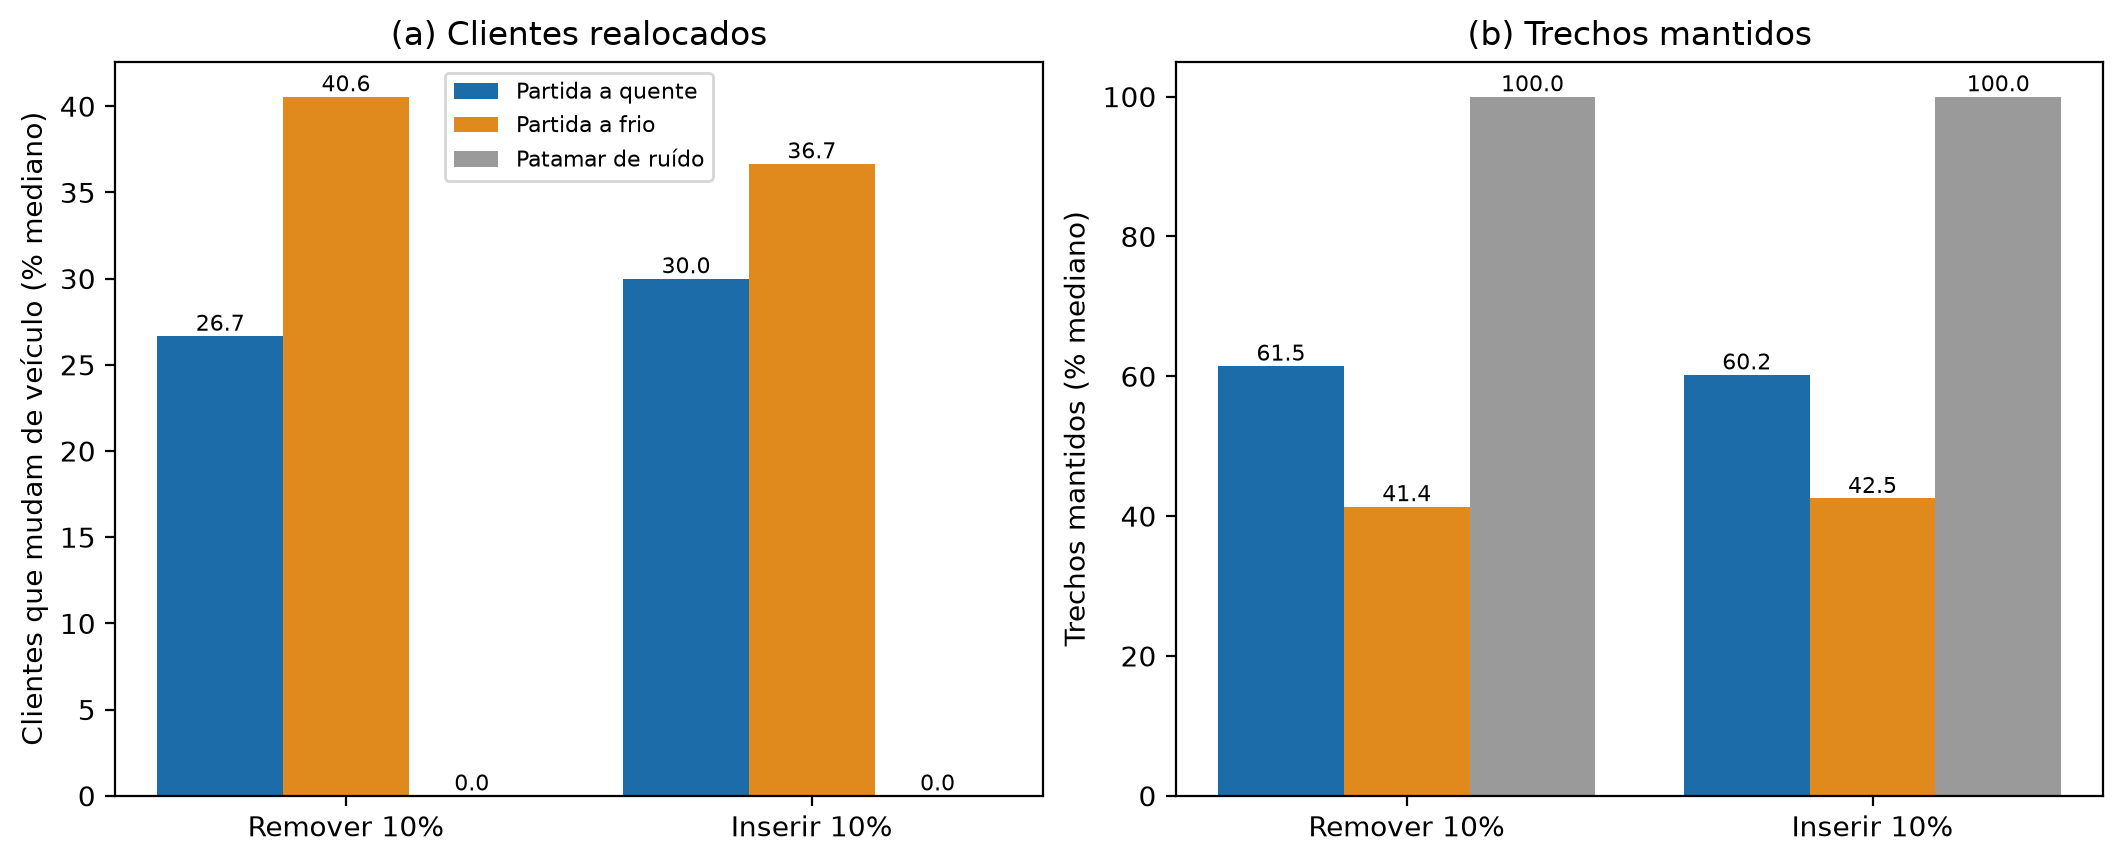

In [9]:
display(eda.localize_columns(phase_c_view.reopt_table_representative(removal, insertion, LANG), LANG))
display(eda.localize_columns(phase_c_view.reopt_noise_table(removal, insertion, LANG), LANG))

viz_robustness.plot_reoptimisation(removal, insertion, LANG)
plt.show()

**Insight.** Partir do plano anterior **preserva mais o plano** e chega a uma distância igual ou melhor; a conclusão se mantém com a réplica representativa de cada instância (as 14 instâncias pesam uma vez por variante). Na remoção de 10%, a reotimização a quente muda de veículo 26,7% dos clientes comuns (mediana das 14 instâncias), contra 40,6% a frio (40,0% com todas as réplicas juntas, a primeira agregação); mantém 64,9% dos pares e 61,5% dos trechos, contra 51,0% e 41,4%; a variação de veículos é −0,57 (quente) e −0,50 (frio) e a da distância, −3,4% e −2,6%. Na inserção de 10%, a quente muda 30,0% dos clientes contra 36,7% a frio (o mesmo valor com as réplicas juntas); mantém 55,2% dos pares e 60,2% dos trechos, contra 46,9% e 42,5%; os veículos aumentam +0,64 e +0,57 e a distância, +6,1% e +7,0%. Mesmo a quente, um evento de 10% dos clientes realoca de 27% a 30% dos demais: o replanejamento tem custo operacional relevante. **O patamar de ruído não é zero na remoção:** das 42 comparações entre réplicas a frio, 4 realocaram clientes (R111, 23,3% em 2 comparações, e RC203, 3,3% em 2 comparações), embora a mediana seja 0,0%; na inserção, 0 de 42 (máximo 0,0%). Há, portanto, variação do solver em 2 das 14 instâncias na remoção, de até 23,3% em R111, e uma diferença quente contra frio desse tamanho em uma única instância não é evidência. **Limitações:** o patamar de ruído foi medido com a máquina ociosa e com 3 réplicas (3 comparações por instância), e execuções com a máquina ocupada podem variar mais (o notebook 06, seção 6, mostra isso); 14 instâncias de desenvolvimento, com a mesma amostra de clientes em remoção e inserção; a partida a quente de inserção usa um plano construído por inserção, não uma solução do solver; as medianas sobre 14 instâncias escondem a variação entre instâncias. **Próxima decisão:** sintetizar.

## 7. Síntese e limitações

**O que os resultados sustentam (descritivamente, na camada B):**

- **Robustez (C1):** os planos otimizados do OR-Tools não são mais frágeis que os das baselines **por cliente** (6,3% de clientes atrasados contra 9,3% e 21,1% com viagem +0–10%; retorno tardio ao depósito cerca de 2 a 3 vezes menor), mas têm **mais rotas com algum atraso** sob choque de serviço (84,2% contra 71,1% e 72,5%). O atraso não é desprezível: mesmo com viagem +0–5%, mais da metade das rotas do OR-Tools tem algum cliente atrasado.
- **A folga explica a fragilidade:** a correlação entre a folga nominal e a taxa de atraso é negativa em todos os casos (−0,37 a −0,78); R1 e RC1 (folga média de 38 a 41) atrasam 13,1% e 11,1% dos clientes com viagem +0–10%, contra 1,0% em C1 (folga de 168).
- **Capacidade (C2.1):** com 90% e 80% de Q, são necessários 0,21 e 0,57 veículo a mais por instância (3 e 6 das 14 instâncias, concentradas nas famílias C, em que a capacidade já limitava a frota), com +13,9% e +13,6% de distância nas instâncias de frota maior; com frota igual, a distância praticamente não muda.
- **Frota limitada com prioridade (C2.2):** com K − 1 e K − 2, o solver deixa de atender cerca de 8 e 25 clientes por instância; a prioridade reduz os prioritários não atendidos de 23 para 0 e de 69 para 3, ao custo de +0,8 e +1,4 cliente comum não atendido por instância. "Não atendido" passa a ser uma decisão explícita de negócio. O número descartado varia entre réplicas da mesma célula (em RC108 com K − 2 e penalidade uniforme, 9, 7 e 7 clientes), porque a penalidade incentiva o atendimento, mas a heurística não garante um descarte mínimo.
- **Reotimização (C3):** partir do plano anterior preserva mais (26,7% contra 40,6% de clientes realocados na remoção; 30,0% contra 36,7% na inserção; réplica representativa de cada instância) e chega a distância igual ou melhor, mas um evento de 10% dos clientes realoca de 27% a 30% dos demais; o patamar de ruído tem mediana 0%, mas não é zero na remoção (4 de 42 comparações entre réplicas a frio realocaram clientes, até 23,3%, em R111 e RC203).

**O que os resultados não sustentam:**

- **Janelas flexíveis (C2.3, exploratório):** só 3 de 14 instâncias foram resolvidas (4 infactíveis por capacidade e 7 com falha na construção inicial em até 1,3 s); o bloco não sustenta conclusão geral, e corrigi-lo exige uma partida a quente não pré-registrada (trabalho futuro).
- Otimalidade, robustez como objetivo ou causas: o solver minimiza frota e distância, e a robustez e o tempo são subprodutos; as explicações oferecidas (rotas mais longas, posição do cliente na rota) são compatíveis com os dados, mas não foram testadas.
- Comparação com o SINTEF ou com uma operação real: a camada B não tem referência externa, e os dados são sintéticos (coordenadas no plano, sem trânsito, demanda e janelas gerados).

**Limitações da fase:** (1) C2.3 falhou em 7 das 10 instâncias possíveis por limitação da construção inicial, e não por tempo; (2) C1 usa planos de avaliação de forma descritiva, com choques independentes por trecho, sem a correlação espacial e temporal do trânsito real; (3) C2 e C3 usam só 14 instâncias de desenvolvimento, e as classes de frota têm de 3 a 8 instâncias; (4) o ganho de robustez e de tempo não é objetivo do solver; (5) o patamar de ruído do C3 foi medido com a máquina ociosa e 3 réplicas, e não é zero na remoção.

**Próximo passo:** a reotimização e os atrasos sugerem, como trabalho futuro, medir a robustez de planos escolhidos com folga mínima por cliente e corrigir o C2.3 com partida a quente, o que exigiria novo protocolo pré-registrado.

## Referências

- Archetti, C., Speranza, M. G., & Vigo, D. (2014). Vehicle routing problems with profits. In P. Toth & D. Vigo (Eds.), *Vehicle routing: Problems, methods, and applications* (2nd ed.). SIAM.
- Gendreau, M., Laporte, G., & Séguin, R. (1996). Stochastic vehicle routing. *European Journal of Operational Research, 88*(1), 3–12.
- Metropolis, N., & Ulam, S. (1949). The Monte Carlo method. *Journal of the American Statistical Association, 44*(247), 335–341.
- Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606.
- Perron, L., & Furnon, V. (2026). *OR-Tools* (Version 9.15) [Computer software]. Google. https://developers.google.com/optimization/
- Pillac, V., Gendreau, M., Guéret, C., & Medaglia, A. L. (2013). A review of dynamic vehicle routing problems. *European Journal of Operational Research, 225*(1), 1–11.
- Spearman, C. (1904). The proof and measurement of association between two things. *The American Journal of Psychology, 15*(1), 72–101.
- Taillard, É., Badeau, P., Gendreau, M., Guertin, F., & Potvin, J.-Y. (1997). A tabu search heuristic for the vehicle routing problem with soft time windows. *Transportation Science, 31*(2), 170–186.